### Разведочный анализ данных. Чекпоинт 2

Для начала импортируем все необходимые библиотеки:

In [18]:
import os # для работы с операционной системой, конкретно, чтобы собрать данные из папок
import h5py # для чтения и записи файлов формата HDF5 (расширение .h5)
import numpy as np
import pandas as pd
import hashlib # библиотека для хеширования. Мы используем её функцию md5, чтобы превратить пиксели картинки в уникальный код (хеш)
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path # удобный способ работы с путями к файлам 
from tqdm import tqdm # для прогресс-баров - у нас много элементов, поэтому будем отслеживать процесс обработки 
from PIL import Image #ля работы с обычными картинками (.jpg, .png)

# Настройки отображения
pd.set_option('display.max_columns', None) # будем видеть все колонки в таблицах
plt.style.use('ggplot') # Симпатичные графики
BASE_PATH = Path("./Data") #переменная, в которой мы сохраняем базовый путь к папке с данными.

Для работы используются три набора данных по спутниковым снимкам, скачанные с kaggle. 
1. EuroSat Dataset - спутниковые снимки нормальной местности. (https://www.kaggle.com/datasets/apollo2506/eurosat-dataset)
2. Wildfire Prediction Dataset (Satellite Images) - отсюда взяты снимки, размеченные как природные пожары. (https://www.kaggle.com/datasets/abdelghaniaaba/wildfire-prediction-dataset)
3. Landslide4Sense - (https://www.kaggle.com/datasets/tekbahadurkshetri/landslide4sense)
Данные разделены на нормальные и аномальные:

- *Нормальные наблюдения (1й датасет).* В него входит 10 классов нормальной местности: "Однолетние культуры", "Лес", "Травянистая растительность", "Шоссе", "Промышленные зоны", 
"Пастбище", "Постоянные урожаные посадки", "Жилые районы", "Река", "Моря-озера".
- *Аномальные наблюдения*:
    - Природные пожары (2й датасет);
    - Оползни (3й датасет).

Выбрав датасеты и скачав их, я открыла и визуально проанализировала изображения: насколько реально человеческим взглядом различить пожары, оползни и нормальную местность. Сразу подметила, что 1 и 2 датасет были с обычным форматом файла, а вот снимки оползней были в формате HDF5. Формат HDF5 (Hierarchical Data Format) - это контейнер, который используется для хранения больших многомерных массивов данных. В отличие от привычных .jpg или .png, которые уже сжаты и готовы к отображению, .h5 файл хранит «сырые» данные в виде тензора. В данном случае внутри файла лежит массив размерностью (128, 128, 14) - то есть изображение 128 на 128 пикселей, состоящее из 14 спектральных каналов (Sentinel-2 снимает Землю не только в видимом RGB-диапазоне, но и в инфракрасном, что полезно для анализа растительности). На этапе подготовки данных передо мной встала задача извлекать RGB-срезы из .h5, чтобы привести все наблюдения к одному виду.

In [ ]:
# Сбор обычных картинок (EuroSat, Wildfire)
def collect_images(root_dir, is_anomaly, anomaly_type=None, ignore_folder=None):
    records = []
    for dirpath, _, filenames in os.walk(root_dir):
        if ignore_folder and ignore_folder in dirpath:
            continue
        for f in filenames:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                records.append({
                    'path': str(Path(dirpath) / f),
                    'label': Path(dirpath).name,
                    'is_anomaly': is_anomaly,
                    'anomaly_type': anomaly_type,
                    'format': 'image'
                })
    return pd.DataFrame(records)

# Сбор оползней (.h5) с проверкой масок
def collect_h5_landslides(img_dir, mask_dir):
    records = []
    for img_path in Path(img_dir).glob('*.h5'):
        # Меняем image_1.h5 на mask_1.h5
        mask_name = img_path.name.replace('image_', 'mask_')
        mask_path = Path(mask_dir) / mask_name
        
        if mask_path.exists():
            try:
                with h5py.File(mask_path, 'r') as f:
                    mask_data = f[list(f.keys())[0]][:]
                    if np.max(mask_data) > 0: # берет .h5 файл маски, достает из него массив чисел и проверяет: Есть ли в этой маске хоть одно значение больше нуля? Если 0, то там просто фон и такой снимок не подходит.
                        records.append({
                            'path': str(img_path),
                            'label': 'landslide',
                            'is_anomaly': 1,
                            'anomaly_type': 'landslide',
                            'format': 'h5'
                        })
            except Exception:
                continue
    return pd.DataFrame(records)

print("Функции сбора данных готовы.")


Функции сбора данных готовы.


In [20]:
print("Собираем нормальные данные (EuroSat)...")
normal_df = collect_images(BASE_PATH / "EuroSat", is_anomaly=0, ignore_folder="allBands")

print("Собираем пожары (Wildfire)...")
fire_df = collect_images(BASE_PATH / "wildfire" / "wildfire", is_anomaly=1, anomaly_type='fire')

print("Собираем оползни (Landslides)...")
landslide_df = collect_h5_landslides(
    BASE_PATH / "Landslides" / "TrainData" / "img", 
    BASE_PATH / "Landslides" / "TrainData" / "mask"
)

# Объединяем аномалии
anomaly_df = pd.concat([fire_df, landslide_df], ignore_index=True)

print("\nСтатистика:")
print(f"Норма (EuroSat): {len(normal_df)}")
print(f"Пожары (Wildfire): {len(fire_df)}")
print(f"Оползни (Landslides): {len(landslide_df)}")

Собираем нормальные данные (EuroSat)...
Собираем пожары (Wildfire)...
Собираем оползни (Landslides)...

Статистика:
Норма (EuroSat): 27000
Пожары (Wildfire): 3480
Оползни (Landslides): 2231


Ранее выяснили какое количество в итоге используется в разведочном анализе. Теперь посмотрим, как выглядят все наборы данных и классы:

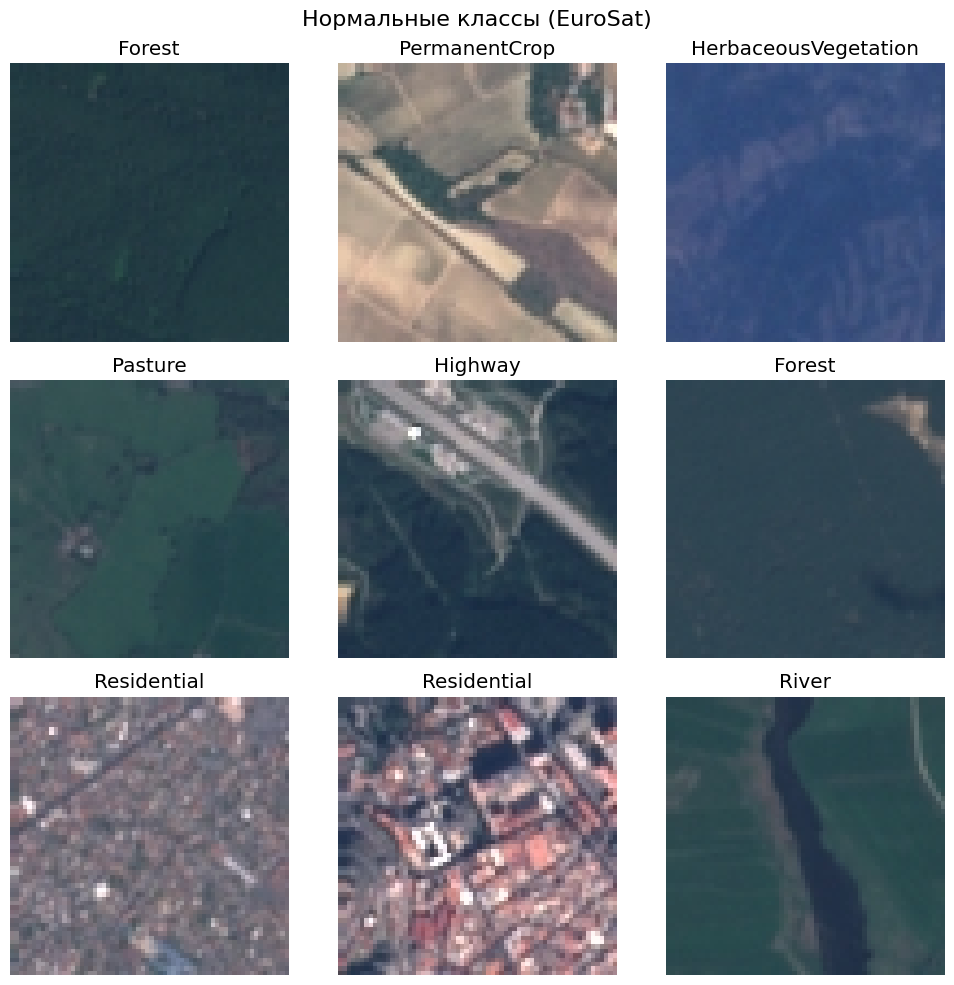

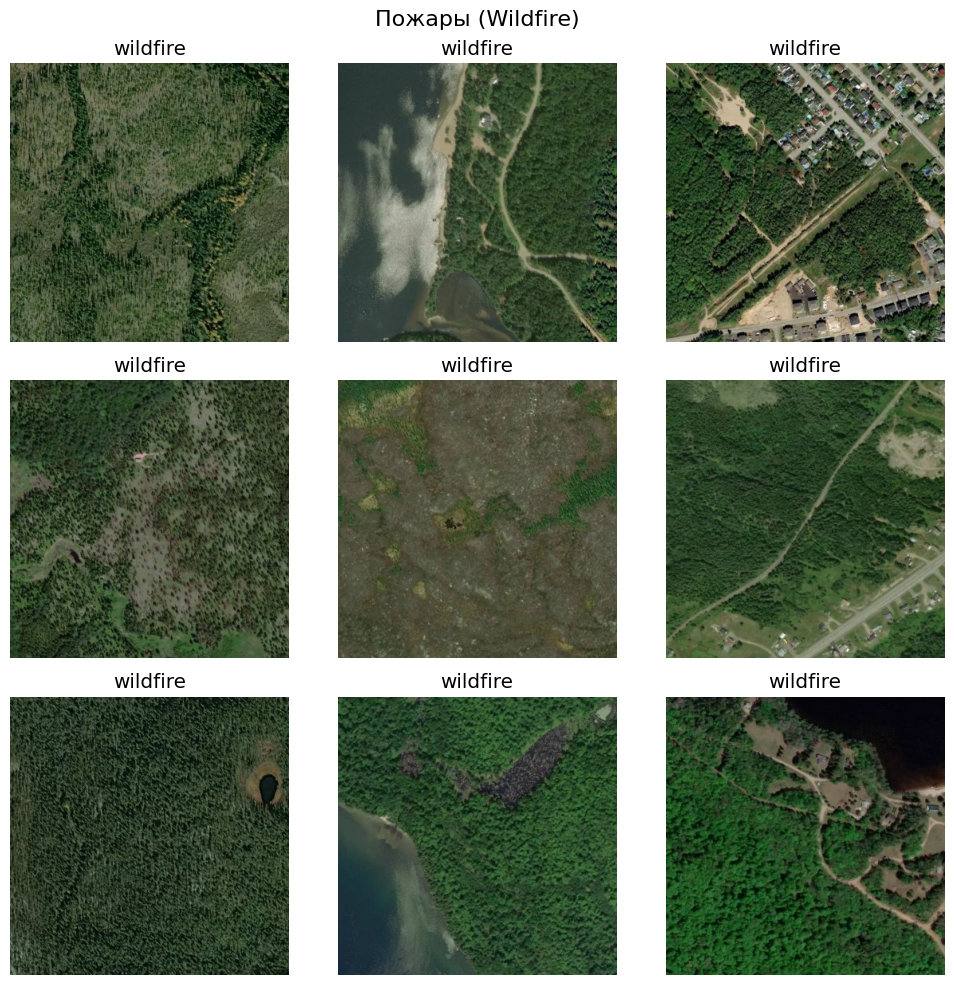

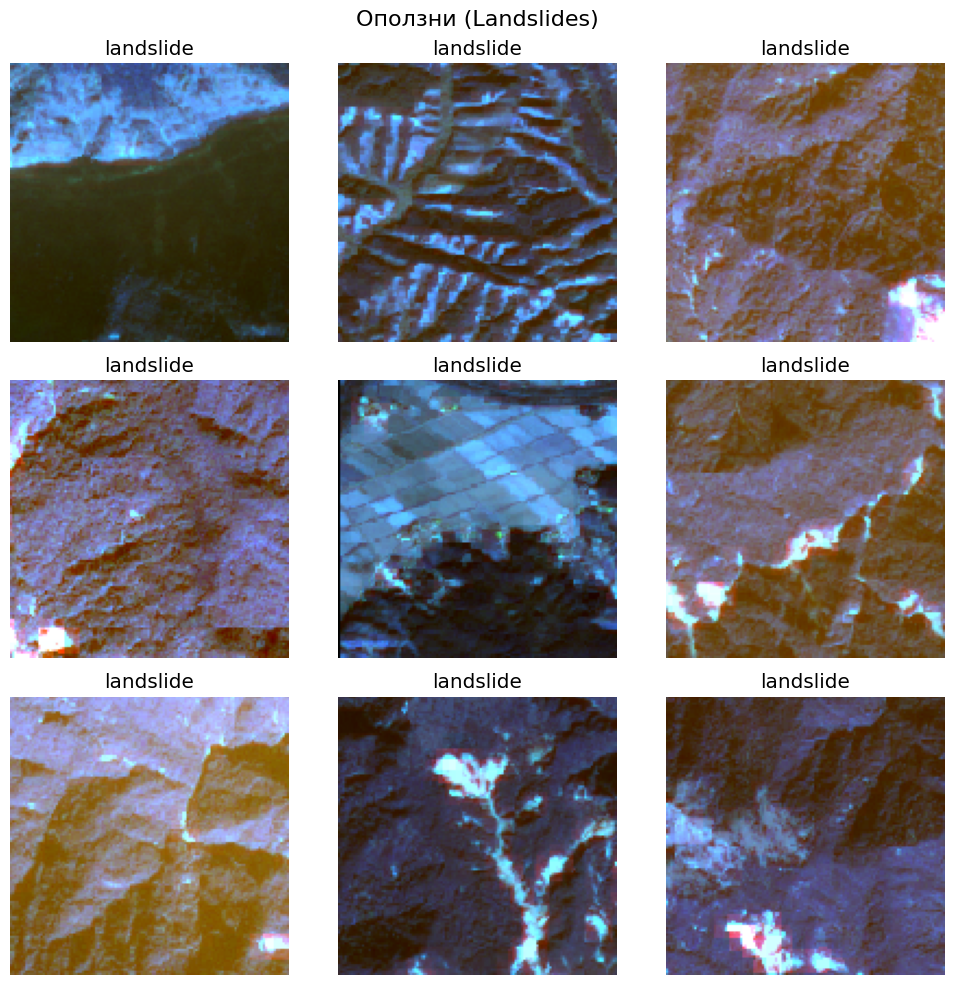

In [4]:
def show_image_grid(df, title, num_rows=3, num_cols=3, is_h5=False):
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 10))
    fig.suptitle(title, fontsize=16)
    
    samples = df.sample(min(num_rows * num_cols, len(df)), random_state=42)
    
    for i, (_, row) in enumerate(samples.iterrows()):
        ax = axes[i // num_cols, i % num_cols]
        
        if is_h5:
            with h5py.File(row['path'], 'r') as f:
                data = f['img'][:]
                rgb = data[:, :, :3] # (128, 128, 3)
                p2, p98 = np.percentile(rgb, (2, 98))
                if p98 > p2: rgb = (rgb - p2) / (p98 - p2)
                rgb = np.clip(rgb, 0, 1)
            ax.imshow(rgb)
        else:
            ax.imshow(Image.open(row['path']).convert('RGB'))
            
        ax.set_title(row['label'])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Визуализация каждой группы
show_image_grid(normal_df, "Нормальные классы (EuroSat)", is_h5=False)
show_image_grid(fire_df, "Пожары (Wildfire)", is_h5=False)
show_image_grid(landslide_df, "Оползни (Landslides)", is_h5=True)

Самое лучшее качество у картинок с лесными пожарами. Но давайте присмотримся: фактически не все картинки отображают пожар. Например, на первом ряду картинок человек точно не отметил бы пожар. На 4,5,7,8,9 изображениях есть темные области и равнинные коричневые территории. При таком разрешении действительно сложно определить, болотистая ли земля перед нами или выжженная "лысая" после пожара. Или, например, очаг возгорания ли это или небольшой водоем с темной цветопередачей снимка. В целом будет справедливо, если модель в будущем отнесет такую картинку к спорной и отправит на проверку человеку. Ошибка первого рода менее критична, чем второго в данном случае. 

Заметим, что у снимков из датасета оползней странный оттенок. Из-за использования мультиспектральных данных Sentinel-2 (где первые три канала - это Blue, Green, Red, а не привычный RGB) изображения имеют неестественный сине-коричневый оттенок. В отличие от обычных RGB-фотографий (как в EuroSat), эти снимки содержат «сырые» спектральные данные, которые требуют сложной нормализации для человеческого глаза. Именно поэтому оползни выглядят как абстрактные текстуры - для человека это просто цветные пятна, но для нейросети это ценная информация о рельефе, влажности и отсутствии растительности, недоступная в обычном RGB. 
(P.s. Как бы модель в будущем не выучила, что странные оттенки означают наличие оползней...)

Проверим целостность файлов:

In [21]:
def audit_images(df, name):
    results = []
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Аудит {name}", leave=False):
        p = row['path']
        try:
            if row['format'] == 'image':
                with Image.open(p) as img:
                    arr = np.array(img.convert('RGB'))
                    results.append({'hash': hashlib.md5(arr.tobytes()).hexdigest(), 'error': None})
            else:
                results.append({'hash': f"h5_{idx}", 'error': None})
        except Exception as e:
            results.append({'hash': None, 'error': str(e)})
    res_df = df.join(pd.DataFrame(results))
    print(f"[{name}] Битых: {res_df['error'].notna().sum()} | Дубликатов: {res_df['hash'].duplicated().sum()}")
    return res_df

normal_audited = audit_images(normal_df, "Норма")
anomaly_audited = audit_images(anomaly_df, "Аномалии")

[Норма] Битых: 0 | Дубликатов: 0


[Аномалии] Битых: 1 | Дубликатов: 0


In [22]:
# Оставляем только те строки, где нет ошибки
anomaly_df = anomaly_df[anomaly_audited['error'].isna()]
print(f"Осталось аномалий после удаления битых файлов: {len(anomaly_df)}")

Осталось аномалий после удаления битых файлов: 5710


В ходе проверки целостности данных не были выявлены битые файлы в нормальном классе и выявлен 1 битый файл в классе аномалий. Дубликатов не обнаружено. Это свидетельствует о высоком качестве исходных данных.

Одним из важнейших этапов разведочного анализа данных для задач классификации является оценка соотношения классов. В реальных задачах мониторинга чрезвычайных ситуаций аномалии (пожары, оползни) встречаются значительно реже, чем нормальный ландшафт. Чтобы наглядно оценить масштаб дисбаланса в нашем датасете, построим столбчатую диаграмму. Так как разница между количеством нормальных снимков и аномалий может быть в десятки раз, мы будем использовать логарифмическую шкалу по оси Y. Это позволит одновременно увидеть и огромный столбец нормы, и маленькие столбцы аномалий. Над каждым столбцом выведем точное количество изображений.

C:\Users\vikas\AppData\Local\Temp\ipykernel_11204\4113500818.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")


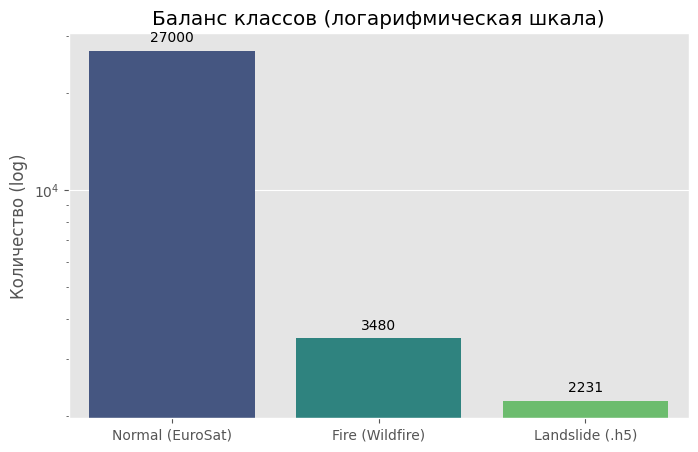

In [23]:
plt.figure(figsize=(8, 5))
class_counts = {
    'Normal (EuroSat)': len(normal_df),
    'Fire (Wildfire)': len(fire_df),
    'Landslide (.h5)': len(landslide_df)
}
ax = sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")
ax.set_yscale("log") 

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), textcoords='offset points')

plt.title('Баланс классов (логарифмическая шкала)')
plt.ylabel('Количество (log)')
plt.show()

#### Выводы:
1. Присутствует сильный дисбаланс. Класс «Норма» содержит 27 000 изображений, что в 7.7 раз больше класса пожаров и в 12 раз больше класса оползней. 
2. Если обучить нейросеть на таких данных без предварительной подготовки, она выучит читерскую стратегию: будет всегда предсказывать класс нормы, так как это дает максимальную точность . Для решения этой проблемы на этапе обучения потребуется использовать взвешивание классов или техники аугментации, чтобы модель обращала больше внимания на редкие классы аномалий.
3. В контексте проекта не будем заставлять модель жестко классифицировать каждый пиксель в один из 3 классов. Вместо этого планируется использовать уверенность модели. Нормальные объекты будут давать высокую уверенность, а редкие аномалии - низкую, что позволит отправлять их на ручную проверку оператору.

Дополнительно визуально оцениваю картинки из датасета пожаров на признак, сколько там вполне нормальных снимков:

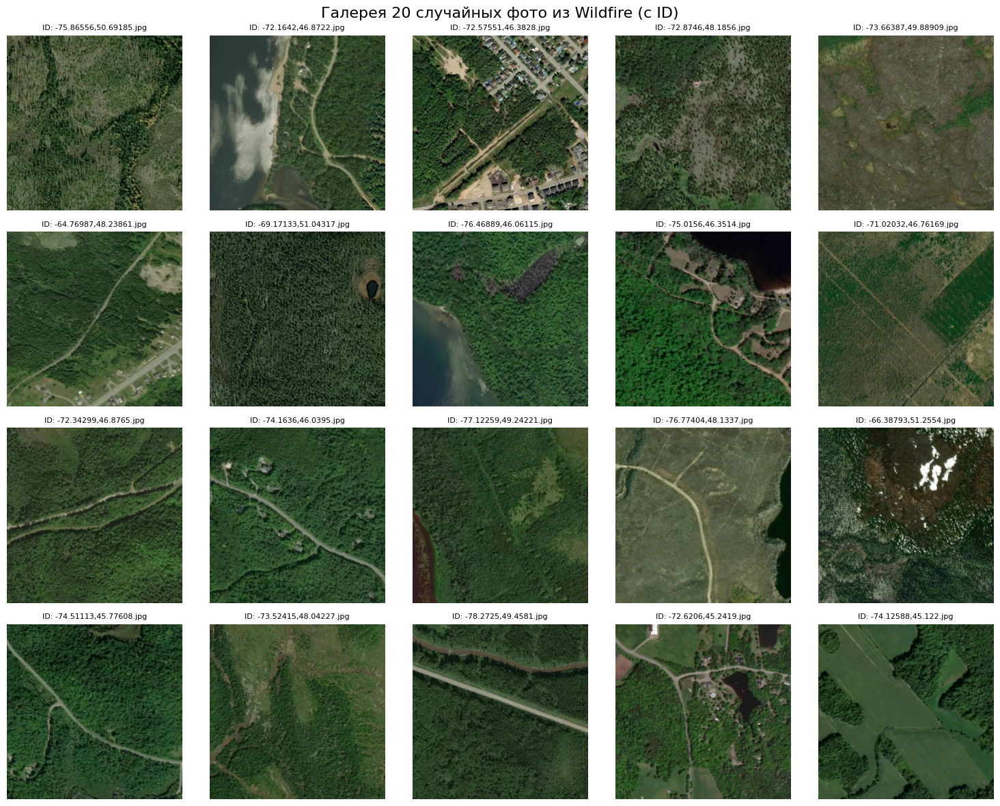

In [ ]:
def show_wildfire_gallery(df, num_images=20):
    # Берем случайные 20 картинок
    samples = df.sample(num_images, random_state=42)
    
    cols = 5
    rows = math.ceil(num_images / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
    fig.suptitle("Галерея 20 случайных фото из Wildfire (с ID)", fontsize=16)
    
    for i, (idx, row) in enumerate(samples.iterrows()):
        ax = axes[i // cols, i % cols]
        
        # Открываем картинку
        img = Image.open(row['path']).convert('RGB')
        ax.imshow(img)
        
        # Берем только имя файла (без пути) как ID
        file_id = row['path'].split('/')[-1].split('\\')[-1] 
        
        # Выводим ID мелким шрифтом
        ax.set_title(f"ID: {file_id}", fontsize=8)
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()

# Запускаем для датасета пожаров
show_wildfire_gallery(fire_df, num_images=20)

Дейстительно, темные области теоретически можно оценить как пожар (по углам картинок, пятна, коричнево-серые земли). 

### Анализ текстурных признаков (Фильтр Собеля)

Цветовые характеристики не всегда позволяют отличить нормальные объекты от аномалий (как увидели ранее, распределения яркости сильно пересекаются). Поэтому следующим шагом разведочного анализа является оценка текстур - пространственной структуры изображения. 

Для визуализации текстур применим оператор Собеля (Sobel filter). Это классический метод компьютерного зрения, который вычисляет градиент яркости изображения. Простыми словами, фильтр Собеля ищет границы объектов: он делает пиксель ярким там, где цвет резко меняется (например, на границе крыши дома или обрыва), и оставляет его темным там, где поверхность однородна (например, гладь воды или ровный лес). 
Далее визуализируем карты границ (в цветовой палитре `hot`, где ярко-желтый — это максимальный перепад, а черный — его отсутствие) для трех групп: нормальных классов, пожаров и оползней.

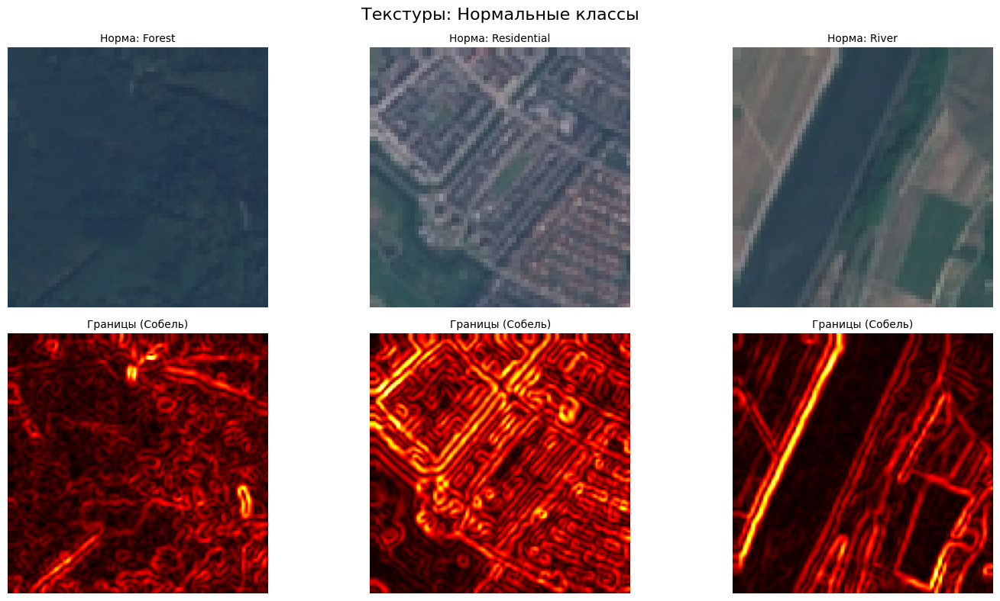

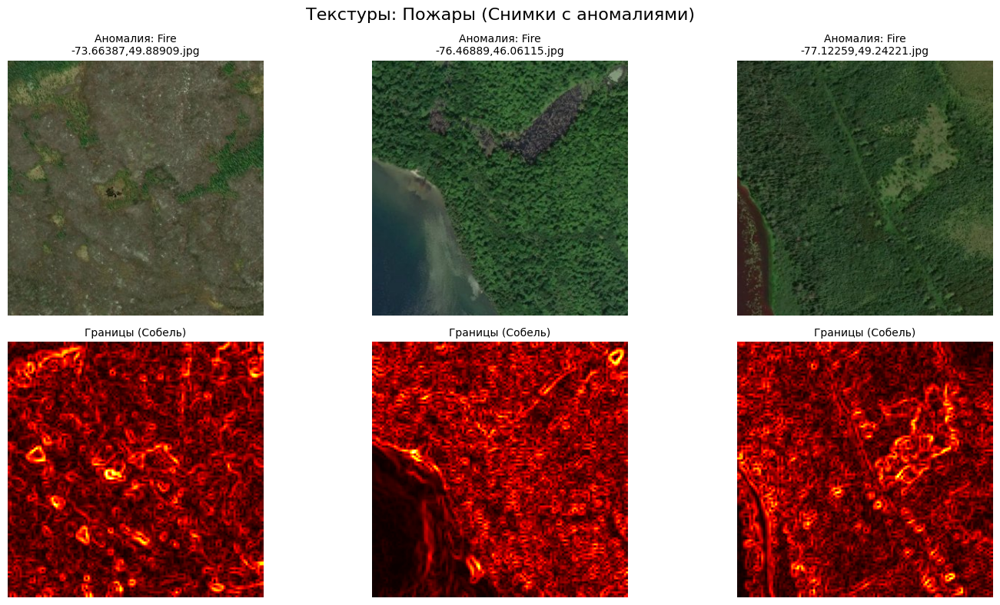

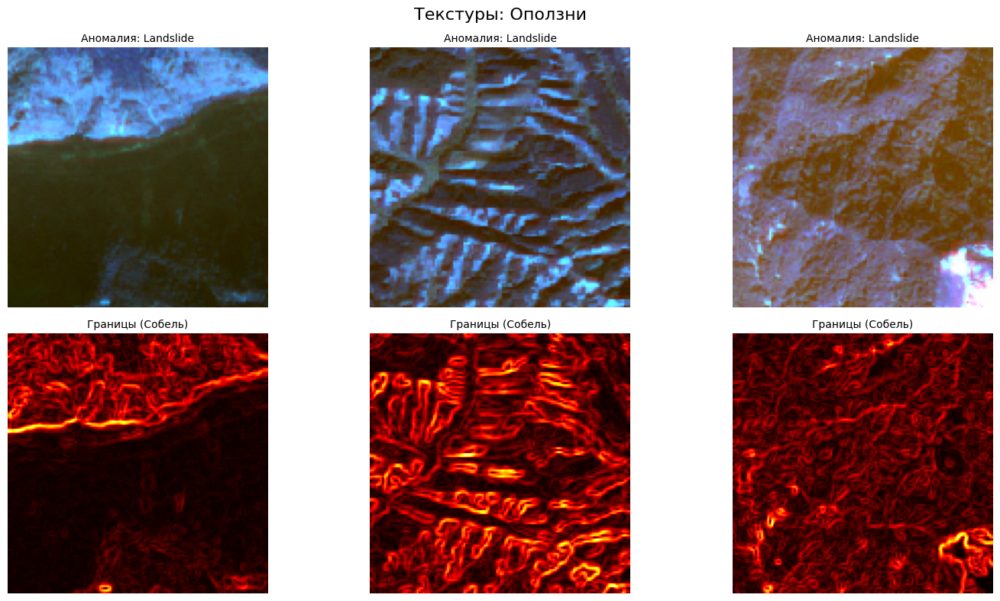

In [26]:
from scipy.ndimage import sobel


# Функция вычисления границ (поддерживает и jpg, и h5)
def get_sobel_edge_scipy(path, is_h5=False):
    if is_h5:
        with h5py.File(path, 'r') as f:
            data = f['img'][:]
            rgb = data[:, :, :3]
            p2, p98 = np.percentile(rgb, (2, 98))
            if p98 > p2: rgb = (rgb - p2) / (p98 - p2)
            rgb = (np.clip(rgb, 0, 1) * 255).astype(np.uint8)
            gray = np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])
    else:
        img = Image.open(path).convert('RGB').resize((128, 128))
        rgb = np.array(img)
        gray = np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])
        
    grad_x = sobel(gray, axis=1)
    grad_y = sobel(gray, axis=0)
    grad = np.hypot(grad_x, grad_y)
    grad = (grad - grad.min()) / (grad.max() - grad.min() + 1e-8)
    return grad

# Универсальная функция отрисовки (принимает список кортежей: (путь, ID_или_название, is_h5))
def plot_texture_grid(items, title):
    fig, axes = plt.subplots(2, len(items), figsize=(5 * len(items), 8))
    fig.suptitle(title, fontsize=16)
    
    for i, (path, label, is_h5) in enumerate(items):
        # 1. Оригинал
        if is_h5:
            with h5py.File(path, 'r') as f:
                data = f['img'][:]
                rgb = data[:, :, :3]
                p2, p98 = np.percentile(rgb, (2, 98))
                if p98 > p2: rgb = (rgb - p2) / (p98 - p2)
                axes[0, i].imshow(np.clip(rgb, 0, 1))
        else:
            axes[0, i].imshow(Image.open(path).convert('RGB'))
        
        axes[0, i].set_title(label, fontsize=10)
        axes[0, i].axis('off')
        
        # 2. Карта границ
        edges = get_sobel_edge_scipy(path, is_h5=is_h5)
        axes[1, i].imshow(edges, cmap='hot')
        axes[1, i].set_title("Границы (Собель)", fontsize=10)
        axes[1, i].axis('off')
        
    plt.tight_layout()
    plt.show()


# --- 1. БЛОК: НОРМА (EuroSat) ---
# Возьмем по одному представителю: Лес, Город, Вода
normal_items = []
for label in ['Forest', 'Residential', 'River']:
    row = normal_df[normal_df['label'] == label].iloc[0]
    normal_items.append((row['path'], f"Норма: {label}", False))
    
plot_texture_grid(normal_items, "Текстуры: Нормальные классы")


# --- 2. БЛОК: ПОЖАРЫ (Wildfire) ---
# Используем ID, которые заведомо похожи на пожары, чтобы оценить структуру
fire_ids = [
    "-73.66387,49.88909.jpg",
    "-76.46889,46.06115.jpg",
    "-77.12259,49.24221.jpg"
]
fire_items = []
for fid in fire_ids:
    path = fire_df[fire_df['path'].str.endswith(fid)].iloc[0]['path']
    fire_items.append((path, f"Аномалия: Fire\n{fid}", False))
    
plot_texture_grid(fire_items, "Текстуры: Пожары (Снимки с аномалиями)")


# --- 3. БЛОК: ОПОЛЗНИ (Landslides) ---
# Берем 3 случайных оползня
landslide_items = []
for _, row in landslide_df.sample(3, random_state=42).iterrows():
    landslide_items.append((row['path'], "Аномалия: Landslide", True))
    
plot_texture_grid(landslide_items, "Текстуры: Оползни")

#### Выводы:
1. Фильтр Собеля четко разделил классы по текстуре. У водных объектов (River) видны только длинные прямые линии береговой линии, а на самой воде границ нет. У леса (Forest) границы размыты и хаотичны. А вот у города (Residential) карта границ крайне плотная — видны кварталы, дороги и крыши домов. 
2. На снимках с пожарами и оползнями фильтр выделяет контуры выгоревших участков, обрывов и поврежденной земли. Лес создает дополнительный шум - в этом случае вырубленная поляна будет выглядеть точно так же, как и выжженная.
3. Результаты подтверждают, что текстурные признаки (плотность границ, направление контуров) являются гораздо более информативными для детекции аномалий, чем простой цвет пикселя. Но нужно иметь в виду, что в текстурном изображении достаточно легко перепутать те или иные артефакты ландшафта.

### Усредненный образ класса 

Чтобы понять, есть ли у каждого класса какая-то общая пространственная структура, мы можем построить «средний портрет» класса. 

Метод Mean Image заключается в следующем: мы берем случайную выборку изображений одного класса, приводим их все к единому размеру (128х128 пикселей) и попиксельно усредняем их значения. 
*   Если объекты в классе имеют общую структуру (например, в городе дома всегда расположены определенным образом), на усредненной картинке проявятся четкие светлые и темные пятна. 
*   Если же класс не имеет фиксированной пространственной композиции (объект может находиться в любом месте снимка), усредненный образ будет выглядеть как размытое цветовое пятно.
Были построены усредненные образы для леса, города, пожаров и оползней, чтобы визуально оценить сложность их внутренней структуры.

Считаем средний пожар...


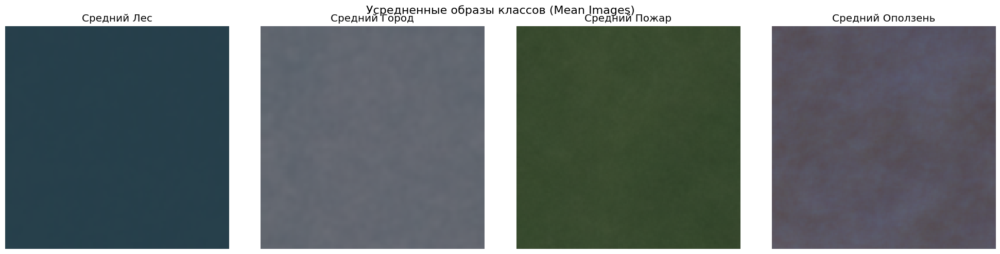

In [27]:
def get_mean_image(df, size=(128, 128), num_samples=100, is_h5=False):
    """Собирает усредненный образ для датафрейма"""
    # Берем случайные картинки 
    samples = df.sample(min(num_samples, len(df)), random_state=42)
    images = []
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc="Усреднение", leave=False):
        try:
            if is_h5:
                with h5py.File(row['path'], 'r') as f:
                    data = f['img'][:]
                    rgb = data[:, :, :3]
                    p2, p98 = np.percentile(rgb, (2, 98))
                    if p98 > p2: rgb = (rgb - p2) / (p98 - p2)
                    # Переводим в 0-1 и ресайзим (через PIL для простоты)
                    rgb_img = Image.fromarray((np.clip(rgb, 0, 1) * 255).astype(np.uint8))
                    rgb_img = rgb_img.resize(size)
                    images.append(np.array(rgb_img) / 255.0)
            else:
                img = Image.open(row['path']).convert('RGB').resize(size)
                images.append(np.array(img) / 255.0)
        except:
            continue
            
    if len(images) == 0:
        return np.zeros((size[1], size[0], 3))
        
    # Усредняем по всем картинкам
    return np.mean(images, axis=0)

# 1. Средний ЛЕС
mean_forest = get_mean_image(normal_df[normal_df['label'] == 'Forest'], num_samples=200)

# 2. Средний ГОРОД
mean_city = get_mean_image(normal_df[normal_df['label'] == 'Residential'], num_samples=200)

# 3. Средний ПОЖАР
print("Считаем средний пожар...")
mean_fire = get_mean_image(fire_df, num_samples=200)

# 4. Средний ОПОЛЗЕНЬ
mean_landslide = get_mean_image(landslide_df, num_samples=200, is_h5=True)

# Отрисовка 
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Усредненные образы классов (Mean Images)", fontsize=16)

axes[0].imshow(mean_forest)
axes[0].set_title("Средний Лес")
axes[0].axis('off')

axes[1].imshow(mean_city)
axes[1].set_title("Средний Город")
axes[1].axis('off')

axes[2].imshow(mean_fire)
axes[2].set_title("Средний Пожар")
axes[2].axis('off')

axes[3].imshow(mean_landslide)
axes[3].set_title("Средний Оползень")
axes[3].axis('off')

plt.tight_layout()
plt.show()

##### Выводы:
1. Усредненный образ города  демонстрирует слабый узор пространственной структуры — видны серые размытые кластеры, а также темные участки. Вероятно, это могли бы быть постройки и дороги соответсвенно. Это означает, что у городов есть общие визуальные паттерны, правда достаточно слабые по интерпретации.
2. Усредненный лес и средний пожар выглядят как однородные темно-зеленые пятна. Это говорит о том, что очаг возгорания может находиться в любой точке снимка, а не только в центре. Средний оползень также не имеет четкой структуры из-за сильной вариативности рельефа и мультиспектрального формата.
3. Полученные образы подтверждают, что для детекции аномалий модель не может полагаться только на глобальные паттерны. Будущая нейросеть должна анализировать локальные признаки на всей площади снимка, а не искать объект в фиксированном центре. Также это подтверждает, что усреднение признаков для поиска аномалий неэффективно.

### Поиск выбросов и аномалий в разметке 

Даже в тщательно собранных датасетах часто встречается шум: битые файлы, снимки с аномальным цветом или объекты, которые случайно попали не в свою папку. Чтобы найти такие выбросы, используем алгоритм машинного обучения *Isolation Forest*.

Принцип его работы прост: алгоритм анализирует числовые признаки каждого изображения (среднюю яркость каналов R, G, B и общий контраст) и ищет объекты, которые статистически сильно отличаются от основной массы своего класса. Для анализа мы передали в алгоритм выборку из 1000 изображений для каждого класса и попросили найти 5% самых нетипичных. 

Считаем признаки для Норма (EuroSat)...


Найдено выбросов в Норма (EuroSat): 50 из 1000
Считаем признаки для Пожары (Wildfire)...


Найдено выбросов в Пожары (Wildfire): 50 из 1000

Смотрим выбросы в Норме (что там могло затесаться?):


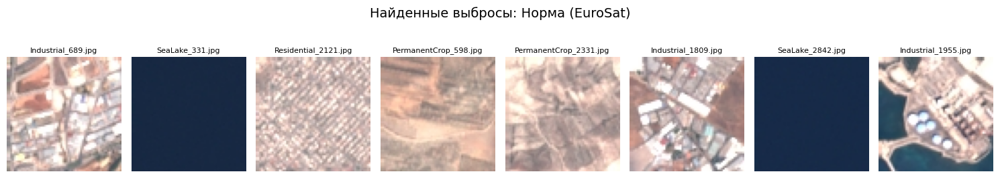


Смотрим выбросы в Пожарах (возможно, это вообще не пожары):


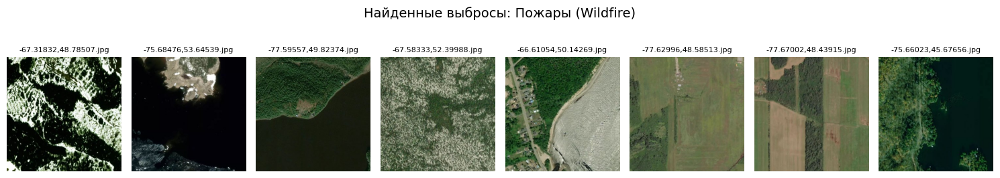

In [28]:
from sklearn.ensemble import IsolationForest


def extract_features_and_find_outliers(df, name, num_samples=1000):
    """Извлекает простые признаки и ищет выбросы"""
    # Берем выборку, чтобы не ждать вечность
    sample = df.sample(min(num_samples, len(df)), random_state=42)
    features = []
    valid_paths = []
    
    print(f"Считаем признаки для {name}...")
    for _, row in tqdm(sample.iterrows(), total=len(sample), leave=False):
        try:
            img = Image.open(row['path']).convert('RGB').resize((64, 64))
            arr = np.array(img) / 255.0
            
            # Признаки: среднее по каналам, контраст (std), общая яркость
            mean_r = arr[:,:,0].mean()
            mean_g = arr[:,:,1].mean()
            mean_b = arr[:,:,2].mean()
            brightness = arr.mean()
            contrast = arr.std()
            
            features.append([mean_r, mean_g, mean_b, brightness, contrast])
            valid_paths.append(row['path'])
        except:
            continue
            
    X = np.array(features)
    
    # Обучаем Isolation Forest
    # contamination=0.05 означает, что мы ожидаем 5% выбросов
    clf = IsolationForest(contamination=0.05, random_state=42)
    preds = clf.fit_predict(X)
    
    # -1 означает выброс, 1 означает "нормальный" объект
    outlier_indices = np.where(preds == -1)[0]
    
    print(f"Найдено выбросов в {name}: {len(outlier_indices)} из {len(valid_paths)}")
    
    # Возвращаем пути найденных выбросов
    return [valid_paths[i] for i in outlier_indices]

# Ищем выбросы в Норме и в Пожарах (для оползней .h5 это не сработает напрямую из-за PIL)
outliers_normal = extract_features_and_find_outliers(normal_df, "Норма (EuroSat)")
outliers_fire = extract_features_and_find_outliers(fire_df, "Пожары (Wildfire)")

# Отображение выбросов
def plot_outliers(paths, title, max_show=8):
    if len(paths) == 0:
        print(f"В группе {title} выбросов не найдено!")
        return
        
    fig, axes = plt.subplots(1, min(len(paths), max_show), figsize=(15, 3))
    fig.suptitle(f"Найденные выбросы: {title}", fontsize=14)
    
    if len(paths) == 1: axes = [axes]
    
    for i, path in enumerate(paths[:max_show]):
        img = Image.open(path).convert('RGB')
        axes[i].imshow(img)
        # Берем только имя файла для заголовка
        filename = path.split('/')[-1].split('\\')[-1]
        axes[i].set_title(filename, fontsize=8)
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

print("\nСмотрим выбросы в Норме (что там могло затесаться?):")
plot_outliers(outliers_normal, "Норма (EuroSat)")

print("\nСмотрим выбросы в Пожарах (возможно, это вообще не пожары):")
plot_outliers(outliers_fire, "Пожары (Wildfire)")

Считаем признаки для Оползни (Landslides)...


  0%|          | 0/1000 [00:00<?, ?it/s]

Найдено выбросов в Оползни (Landslides): 50 из 1000

Смотрим выбросы в Оползнях:


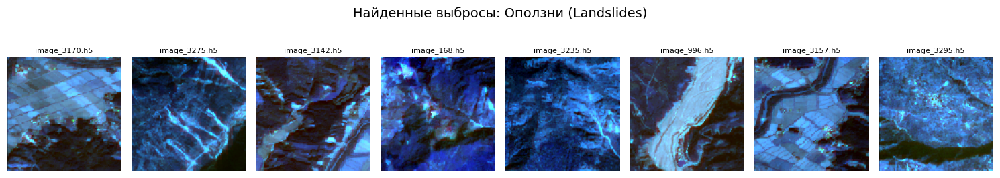

In [29]:
def find_h5_outliers(df, name, num_samples=1000):
    """Извлекает признаки из .h5 и ищет выбросы"""
    sample = df.sample(min(num_samples, len(df)), random_state=42)
    features = []
    valid_paths = []
    
    print(f"Считаем признаки для {name}...")
    for _, row in tqdm(sample.iterrows(), total=len(sample), leave=False):
        try:
            with h5py.File(row['path'], 'r') as f:
                data = f['img'][:]
                rgb = data[:, :, :3]
                
                # Считаем статистику по сырым данным (до нормализации)
                mean_r = rgb[:,:,0].mean()
                mean_g = rgb[:,:,1].mean()
                mean_b = rgb[:,:,2].mean()
                brightness = rgb.mean()
                contrast = rgb.std()
                
                features.append([mean_r, mean_g, mean_b, brightness, contrast])
                valid_paths.append(row['path'])
        except:
            continue
            
    X = np.array(features)
    
    # Ищем выбросы
    clf = IsolationForest(contamination=0.05, random_state=42)
    preds = clf.fit_predict(X)
    outlier_indices = np.where(preds == -1)[0]
    
    print(f"Найдено выбросов в {name}: {len(outlier_indices)} из {len(valid_paths)}")
    return [valid_paths[i] for i in outlier_indices]

# Ищем выбросы среди оползней
outliers_landslide = find_h5_outliers(landslide_df, "Оползни (Landslides)")

def plot_h5_outliers(paths, title, max_show=8):
    if len(paths) == 0:
        print(f"В группе {title} выбросов не найдено!")
        return
        
    fig, axes = plt.subplots(1, min(len(paths), max_show), figsize=(15, 3))
    fig.suptitle(f"Найденные выбросы: {title}", fontsize=14)
    
    if len(paths) == 1: axes = [axes]
    
    for i, path in enumerate(paths[:max_show]):
        with h5py.File(path, 'r') as f:
            data = f['img'][:]
            rgb = data[:, :, :3]
            p2, p98 = np.percentile(rgb, (2, 98))
            if p98 > p2: rgb = (rgb - p2) / (p98 - p2)
            rgb_img = np.clip(rgb, 0, 1)
            
        axes[i].imshow(rgb_img)
        filename = path.split('/')[-1].split('\\')[-1]
        axes[i].set_title(filename, fontsize=8)
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

print("\nСмотрим выбросы в Оползнях:")
plot_h5_outliers(outliers_landslide, "Оползни (Landslides)")

##### Выводы по найденным выбросам:
1. В качестве выбросов нормального класса алгоритм выделил темные однородные снимки (класс `SeaLake`) и очень светлые/контрастные снимки. Это ожидаемо, так как они сильно отличаются по яркости от лесов и полей.
2. Анализ выявил серьезную проблему - шум. Большинство найденных выбросов не содержат никаких признаков пожара. На снимках видны обычные поля, вырубка, дороги и вода. Вероятно, придется искать (не смогла найти датасет лучше этого), либо самостоятельно собирать более показательные снимки пожаров и поврежденных земель.
3. Среди выбросов в наборе оползней оказались снимки с явными артефактами сенсора (например, аномально яркие синие полосы) или снимки с минимальной площадью повреждения.
4. Наличие такого шума означает, что для следующих этапов потребуется либо ручная фильтрация данных, либо применение методов обучения, устойчивых к шуму, чтобы модель не выучила ложные признаки.

Что буду делать дальше:
1.  Так как был выявлен значительный шум в разметке (в классе пожаров присутствуют снимки без явных признаков огня), буду искать либо новый датасет, либо вручную дорабатывать этот (благо, там не так много изображений).
2. Выбирать методы, подходящие под дисбаланс классов и возможную слабую текстурную разницу снимков.
3. Применять методы, сравнивать, записывать даже неудачные варианты.